# SenseForge — Comi-Lingua Token-Level Language Identification

## Objective
Train and evaluate a supervised token-level language identification model on the cleaned Comi-Lingua dataset.

## Dataset
- Training: 428,197 tokens
- Validation: 92,552 tokens
- Test: 91,173 tokens
- Six original annotation labels

## Model
Character n-gram TF-IDF + Logistic Regression.

## Evaluation protocol
- Sentence-group-separated data
- Validation-based model selection
- Held-out test evaluation
- Accuracy, macro precision, macro recall, Macro-F1
- Per-class classification report and confusion matrix

The original six-label annotation scheme is retained. Results must not be interpreted as a normalized three-language classifier.

In [5]:
from pathlib import Path
import json
import time
import random

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

BASE = (
    ROOT / "artifacts" / "senseforge_final"
    / "comilingua_lid"
)

DATA = BASE / "clean_splits"
OUT = BASE / "training_v1"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

LABELS = ["hi", "en", "ot", "h", "e", "u"]

train_df = pd.read_parquet(DATA / "train.parquet")
val_df = pd.read_parquet(DATA / "validation.parquet")
test_df = pd.read_parquet(DATA / "test.parquet")

for name, frame in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    assert {"token", "label", "sentence_group"}.issubset(frame)
    assert frame["token"].notna().all()
    assert frame["label"].isin(LABELS).all()

    print(
        f"{name:12} | "
        f"{len(frame):7,} tokens | "
        f"{frame['sentence_group'].nunique():5,} sentences"
    )

groups = {
    name: set(frame["sentence_group"].astype(str))
    for name, frame in [
        ("train", train_df),
        ("validation", val_df),
        ("test", test_df)
    ]
}

assert not (groups["train"] & groups["validation"])
assert not (groups["train"] & groups["test"])
assert not (groups["validation"] & groups["test"])

assert len(train_df) == 428197
assert len(val_df) == 92552
assert len(test_df) == 91173

print("\nDataset integrity passed.")
print("Output:", OUT)

train        | 428,197 tokens | 21,884 sentences
validation   |  92,552 tokens | 4,688 sentences
test         |  91,173 tokens | 4,689 sentences

Dataset integrity passed.
Output: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1


SENSEFORGE — COMI-LINGUA TOKEN LID

Label distribution:


,Train,Validation,Test
label,,,
hi,204112,44129,42234
en,68608,15325,14589
ot,27110,6055,5772
h,88819,18865,20014
e,28441,5823,6177
u,11107,2355,2387


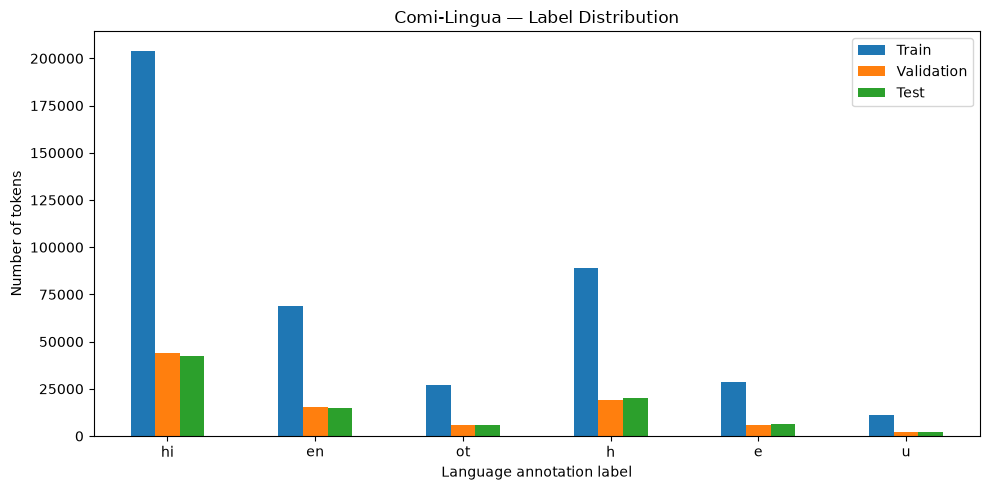


Preparing supervised learning data...
Training examples: 428197
Validation examples: 92552
Classes: ['hi', 'en', 'ot', 'h', 'e', 'u']

Model architecture:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(analyzer='char', dtype=<class 'numpy.float32'>,
                                 max_features=120000, min_df=3,
                                 ngram_range=(2, 5), sublinear_tf=True)),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=500,
                                    random_state=42))])

STARTING SUPERVISED TRAINING

Training finished.
Training time: 37.4 seconds
Learned TF-IDF features: 79235
No convergence warnings reported.

VALIDATION EVALUATION
accuracy            : 0.5270
macro_precision     : 0.5365
macro_recall        : 0.5787
macro_f1            : 0.5014

Detailed classification report:
              precision    recall  f1-score   support

          hi       0.78      0.41      0.54     44129
          en 

,token,label,predicted_label,agreement
3,:,ot,u,3
4,देश,hi,h,3
5,में,hi,h,3
6,कोरोना,hi,h,3
7,महामारी,hi,h,3
8,की,hi,h,3
10,लहर,hi,h,3
11,के,hi,h,3
12,साथ,hi,h,3
13,ही,hi,h,3


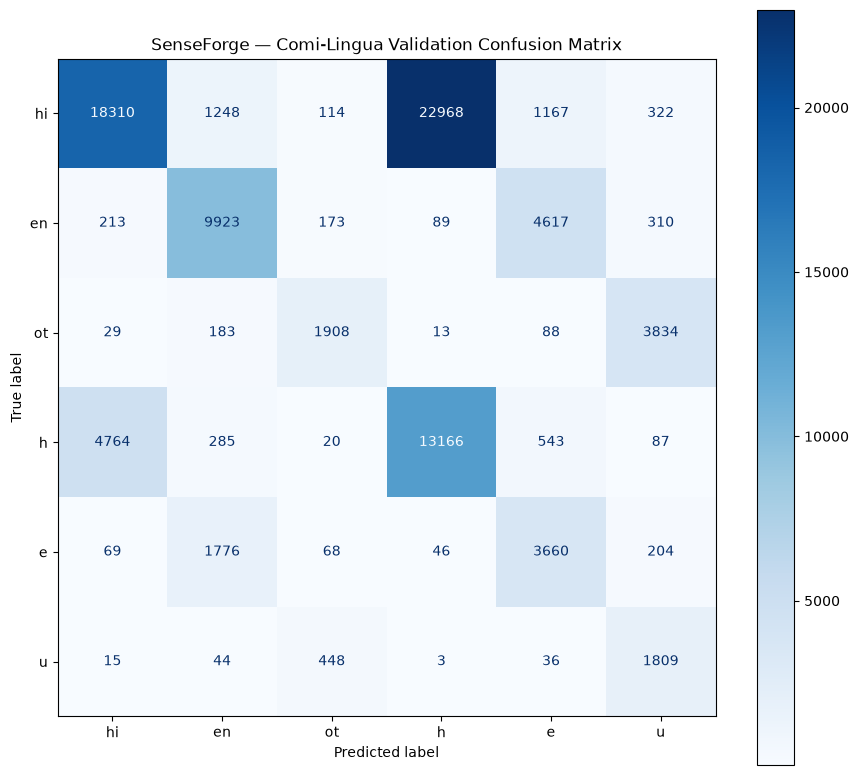


Per-class validation performance:


,precision,recall,f1-score,support
hi,0.782479,0.414920,0.542286,44129.0
en,0.737276,0.647504,0.689480,15325.0
ot,0.698645,0.315111,0.434327,6055.0
h,0.362850,0.697906,0.477461,18865.0
e,0.361982,0.628542,0.459395,5823.0
u,0.275510,0.768153,0.405560,2355.0



TRAINING ARTIFACTS SAVED
Model: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1/comilingua_lid_baseline.joblib
Metadata: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1/training_metadata.json
Error analysis: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1/validation_errors.csv
Confusion matrix: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1/validation_confusion_matrix.png

TOKEN-LEVEL INFERENCE DEMONSTRATION
hello              -> en
namaste            -> en
computer           -> en
भारत               -> h
school             -> en
ka                 -> hi
hai                -> hi
tutorial           -> en
नमस्ते             -> h
learning           -> e
@someone           -> u
123                -> u

COMI-LINGUA BASELINE T

In [7]:
# ============================================================
# SenseForge — Comi-Lingua Token-Level Language Identification
# Character n-gram baseline | Training + validation + analysis
# ============================================================

import json
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.exceptions import ConvergenceWarning


# ------------------------------------------------------------
# 1. Take a final look at the data
# ------------------------------------------------------------
# Before fitting anything, let's confirm how the six labels
# are distributed across our cleaned dataset partitions.

print("=" * 65)
print("SENSEFORGE — COMI-LINGUA TOKEN LID")
print("=" * 65)

label_distribution = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(LABELS).fillna(0).astype(int)

print("\nLabel distribution:")
display(label_distribution)

ax = label_distribution.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Comi-Lingua — Label Distribution")
ax.set_xlabel("Language annotation label")
ax.set_ylabel("Number of tokens")

plt.tight_layout()
plt.savefig(
    OUT / "label_distribution.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 2. Prepare the training and validation examples
# ------------------------------------------------------------
# This first model looks at individual tokens rather than
# entire sentences. Character n-grams are useful here because
# spelling patterns often reveal language information.
#
# For example, "namaste", "tutorial", and "भारत" have very
# different character patterns.
#
# The model won't understand sentence context yet. That is
# something we can explore with a contextual transformer later.

X_train = train_df["token"].astype(str).tolist()
y_train = train_df["label"].astype(str).to_numpy()

X_val = val_df["token"].astype(str).tolist()
y_val = val_df["label"].astype(str).to_numpy()

print("\nPreparing supervised learning data...")
print("Training examples:", len(X_train))
print("Validation examples:", len(X_val))
print("Classes:", LABELS)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert set(y_train).issubset(set(LABELS))
assert set(y_val).issubset(set(LABELS))


# ------------------------------------------------------------
# 3. Build the character-level classifier
# ------------------------------------------------------------
# TF-IDF converts character sequences into numerical features.
# Logistic Regression then learns which patterns are associated
# with each of the six annotation labels.
#
# This is a proper supervised ML baseline, not a hardcoded
# dictionary or a collection of language detection rules.

lid_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            min_df=3,
            max_features=120000,
            sublinear_tf=True,
            lowercase=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=500,
            class_weight="balanced",
            solver="lbfgs",
            random_state=42
        )
    )
])

print("\nModel architecture:")
print(lid_model)


# ------------------------------------------------------------
# 4. Train the classifier
# ------------------------------------------------------------
# This is the main training stage.
#
# The vectorizer learns a vocabulary of character n-grams
# from training data only.
#
# The classifier then optimizes its parameters using the
# human-annotated majority-vote token labels.
#
# Validation and test examples are not used for fitting.

print("\n" + "=" * 65)
print("STARTING SUPERVISED TRAINING")
print("=" * 65)

start_time = time.perf_counter()

with warnings.catch_warnings(record=True) as captured:
    warnings.simplefilter("always", ConvergenceWarning)

    lid_model.fit(X_train, y_train)

training_seconds = time.perf_counter() - start_time

convergence_warnings = [
    str(w.message)
    for w in captured
    if issubclass(w.category, ConvergenceWarning)
]

print("\nTraining finished.")
print(
    "Training time:",
    round(training_seconds, 2),
    "seconds"
)

print(
    "Learned TF-IDF features:",
    len(lid_model.named_steps["tfidf"].vocabulary_)
)

if convergence_warnings:
    print("\nConvergence warnings detected:")
    for message in convergence_warnings[:3]:
        print("-", message)
else:
    print("No convergence warnings reported.")


# ------------------------------------------------------------
# 5. Evaluate on the validation partition
# ------------------------------------------------------------
# We evaluate on sentences that were separated from the
# training partition during data preparation.
#
# Accuracy tells us how often the model is correct overall.
# Macro-F1 gives equal importance to all six labels, which
# matters because their frequencies are quite different.

print("\n" + "=" * 65)
print("VALIDATION EVALUATION")
print("=" * 65)

val_predictions = lid_model.predict(X_val)

def calculate_metrics(y_true, y_pred):
    return {
        "accuracy": float(
            accuracy_score(y_true, y_pred)
        ),
        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                labels=LABELS,
                average="macro",
                zero_division=0
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                labels=LABELS,
                average="macro",
                zero_division=0
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                labels=LABELS,
                average="macro",
                zero_division=0
            )
        )
    }

validation_metrics = calculate_metrics(
    y_val,
    val_predictions
)

for metric, value in validation_metrics.items():
    print(f"{metric:20}: {value:.4f}")

print("\nDetailed classification report:")

validation_report = classification_report(
    y_val,
    val_predictions,
    labels=LABELS,
    zero_division=0
)

print(validation_report)


# ------------------------------------------------------------
# 6. Understand where the model makes mistakes
# ------------------------------------------------------------
# Instead of looking only at accuracy, we want to know which
# labels the model confuses.
#
# This is particularly important because the dataset contains
# both short and full annotation conventions.

validation_errors = val_df.copy()

validation_errors["predicted_label"] = val_predictions

validation_errors = validation_errors[
    validation_errors["label"]
    != validation_errors["predicted_label"]
].copy()

error_rate = len(validation_errors) / len(val_df)

print("\n" + "=" * 65)
print("VALIDATION ERROR ANALYSIS")
print("=" * 65)

print("Incorrect predictions:", len(validation_errors))
print("Error rate:", round(error_rate * 100, 2), "%")

print("\nMost common label confusions:")

confusions = (
    validation_errors
    .groupby(["label", "predicted_label"])
    .size()
    .sort_values(ascending=False)
)

print(confusions.head(15))

print("\nExample misclassified tokens:")

display(
    validation_errors[
        [
            "token",
            "label",
            "predicted_label",
            "agreement"
        ]
    ].head(30)
)

validation_errors.to_csv(
    OUT / "validation_errors.csv",
    index=False
)


# ------------------------------------------------------------
# 7. Visualize the confusion matrix
# ------------------------------------------------------------
# Rows represent the human-annotated labels.
# Columns represent the model's predictions.
#
# A strong diagonal means the model is learning the classes
# correctly. Off-diagonal values reveal systematic confusion.

cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=LABELS
)

fig, ax = plt.subplots(figsize=(9, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABELS
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title(
    "SenseForge — Comi-Lingua Validation Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    OUT / "validation_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. Compare performance across individual labels
# ------------------------------------------------------------
# Overall accuracy can hide weaknesses in less frequent
# classes. This table makes those differences easier to see.

report_dict = classification_report(
    y_val,
    val_predictions,
    labels=LABELS,
    output_dict=True,
    zero_division=0
)

per_class = pd.DataFrame({
    label: report_dict[label]
    for label in LABELS
}).T

per_class = per_class[
    ["precision", "recall", "f1-score", "support"]
]

print("\nPer-class validation performance:")
display(per_class)

per_class.to_csv(
    OUT / "validation_per_class_metrics.csv"
)


# ------------------------------------------------------------
# 9. Save the trained model
# ------------------------------------------------------------
# We save the complete sklearn pipeline, including TF-IDF
# vocabulary and classifier parameters.
#
# This allows us to load the model later without fitting
# the vectorizer again.

model_path = OUT / "comilingua_lid_baseline.joblib"

joblib.dump(
    lid_model,
    model_path
)

metadata = {
    "project": "SenseForge",
    "task": "token_level_language_identification",
    "model": "character_tfidf_logistic_regression",
    "dataset": "Comi-Lingua",
    "training_examples": len(X_train),
    "validation_examples": len(X_val),
    "labels": LABELS,
    "training_seconds": training_seconds,
    "tfidf_features": len(
        lid_model.named_steps["tfidf"].vocabulary_
    ),
    "validation_metrics": validation_metrics,
    "convergence_warnings": convergence_warnings,
    "test_evaluated": False,
    "limitations": [
        "The classifier uses token text without sentence context.",
        "The original six-label annotation conventions are preserved.",
        "The dataset was regrouped to prevent exact sentence overlap.",
        "Near-duplicate and source-level leakage remain unaudited."
    ]
}

metadata_path = OUT / "training_metadata.json"

metadata_path.write_text(
    json.dumps(
        metadata,
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("\n" + "=" * 65)
print("TRAINING ARTIFACTS SAVED")
print("=" * 65)

print("Model:", model_path)
print("Metadata:", metadata_path)
print("Error analysis:", OUT / "validation_errors.csv")
print("Confusion matrix:", OUT / "validation_confusion_matrix.png")


# ------------------------------------------------------------
# 10. Quick inference demonstration
# ------------------------------------------------------------
# These examples help us verify that the saved classifier
# can make predictions on individual unseen token strings.
#
# These are demonstrations, not a substitute for validation
# or held-out test evaluation.

demo_tokens = [
    "hello",
    "namaste",
    "computer",
    "भारत",
    "school",
    "ka",
    "hai",
    "tutorial",
    "नमस्ते",
    "learning",
    "@someone",
    "123"
]

demo_predictions = lid_model.predict(demo_tokens)

print("\n" + "=" * 65)
print("TOKEN-LEVEL INFERENCE DEMONSTRATION")
print("=" * 65)

for token, label in zip(
    demo_tokens,
    demo_predictions
):
    print(f"{token:18} -> {label}")

print("\n" + "=" * 65)
print("COMI-LINGUA BASELINE TRAINING COMPLETE")
print("=" * 65)

print("Validation accuracy:", validation_metrics["accuracy"])
print("Validation Macro-F1:", validation_metrics["macro_f1"])
print("Held-out test: NOT YET EVALUATED")
print("Artifacts:", OUT)

In [9]:
from collections import Counter
import pandas as pd

print("=== LABEL CONVENTION DIAGNOSTIC ===")

# Inspect whether the same token appears with
# different labels across the training data.
token_labels = (
    train_df.groupby("token")["label"]
    .agg(lambda x: Counter(x).most_common())
)

ambiguous_tokens = []

for token, counts in token_labels.items():
    if len(counts) > 1:
        ambiguous_tokens.append({
            "token": token,
            "label_counts": dict(counts),
            "total": sum(n for _, n in counts)
        })

ambiguous_df = pd.DataFrame(ambiguous_tokens)

print("Tokens with multiple labels:", len(ambiguous_df))

if not ambiguous_df.empty:
    display(
        ambiguous_df.sort_values(
            "total", ascending=False
        ).head(30)
    )

# Check label pairs for representative tokens.
examples = [
    "भारत", "नमस्ते", "में", "है",
    "ka", "hai", "naam",
    "computer", "learning", "tutorial",
    ".", "123"
]

print("\nRepresentative token label distributions:")

for token in examples:
    counts = Counter(
        train_df.loc[
            train_df["token"] == token,
            "label"
        ]
    )
    print(f"{token:15} {dict(counts)}")

=== LABEL CONVENTION DIAGNOSTIC ===
Tokens with multiple labels: 14492


,token,label_counts,total
8154,के,"{'hi': 8253, 'h': 4279}",12532
12119,में,"{'hi': 6132, 'h': 3159}",9291
8117,की,"{'hi': 4555, 'h': 2344, 'en': 2}",6901
8249,को,"{'hi': 3859, 'h': 1930}",5789
519,",","{'ot': 3722, 'u': 1943, 'hi': 1}",5666
14405,है।,"{'hi': 3416, 'h': 1796}",5212
527,.,"{'ot': 3418, 'u': 1769, 'hi': 1}",5188
7770,और,"{'hi': 3222, 'h': 1691}",4913
10315,ने,"{'hi': 3227, 'h': 1415}",4642
13938,से,"{'hi': 2857, 'h': 1522}",4379



Representative token label distributions:
भारत            {'hi': 771, 'h': 558}
नमस्ते          {'h': 3}
में             {'hi': 6132, 'h': 3159}
है              {'hi': 1201, 'h': 531}
ka              {'hi': 682, 'h': 81}
hai             {'hi': 2301, 'h': 412}
naam            {'hi': 65, 'h': 8}
computer        {'en': 6, 'e': 1}
learning        {'en': 2, 'e': 3}
tutorial        {'en': 113}
.               {'ot': 3418, 'hi': 1, 'u': 1769}
123             {'u': 1}


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from collections import Counter

NORMALIZE = {
    "hi": "hi",
    "h": "hi",
    "en": "en",
    "e": "en",
    "ot": "other",
    "u": "other"
}

THREE_LABELS = ["hi", "en", "other"]

normalized_gold = [
    NORMALIZE[label]
    for label in y_val
]

normalized_pred = [
    NORMALIZE[label]
    for label in val_predictions
]

print("=== SIX-CLASS MODEL: NORMALIZED EVALUATION ===")

print(
    "Accuracy:",
    accuracy_score(normalized_gold, normalized_pred)
)

print(
    "Macro-F1:",
    f1_score(
        normalized_gold,
        normalized_pred,
        labels=THREE_LABELS,
        average="macro",
        zero_division=0
    )
)

print("\nClassification report:")
print(classification_report(
    normalized_gold,
    normalized_pred,
    labels=THREE_LABELS,
    zero_division=0
))

same_family_errors = sum(
    gold != pred and NORMALIZE[gold] == NORMALIZE[pred]
    for gold, pred in zip(y_val, val_predictions)
)

print("\nErrors within proposed label families:",
      same_family_errors)

print("Total original errors:",
      sum(g != p for g, p in zip(y_val, val_predictions)))

=== SIX-CLASS MODEL: NORMALIZED EVALUATION ===
Accuracy: 0.9419893681389921
Macro-F1: 0.9207187559520199

Classification report:
              precision    recall  f1-score   support

          hi       0.99      0.94      0.97     62994
          en       0.85      0.94      0.89     21148
       other       0.86      0.95      0.90      8410

    accuracy                           0.94     92552
   macro avg       0.90      0.95      0.92     92552
weighted avg       0.95      0.94      0.94     92552


Errors within proposed label families: 38407
Total original errors: 43776


In [13]:
# ============================================================
# SenseForge — Normalized 3-Class Token LID Training
# ============================================================

import time
import json
import joblib
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

NORMALIZE = {
    "hi": "hi",
    "h": "hi",
    "en": "en",
    "e": "en",
    "ot": "other",
    "u": "other"
}

THREE_LABELS = ["hi", "en", "other"]

y_train_3 = np.array([
    NORMALIZE[label]
    for label in y_train
])

y_val_3 = np.array([
    NORMALIZE[label]
    for label in y_val
])

model_3 = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(2, 5),
            min_df=3,
            max_features=120000,
            sublinear_tf=True,
            lowercase=True,
            dtype=np.float32
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=500,
            class_weight="balanced",
            random_state=42
        )
    )
])

print("=== THREE-CLASS TRAINING ===")

start = time.perf_counter()

model_3.fit(X_train, y_train_3)

duration = time.perf_counter() - start

val_pred_3 = model_3.predict(X_val)

metrics_3 = {
    "accuracy": float(
        accuracy_score(y_val_3, val_pred_3)
    ),
    "macro_precision": float(
        precision_score(
            y_val_3, val_pred_3,
            labels=THREE_LABELS,
            average="macro",
            zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            y_val_3, val_pred_3,
            labels=THREE_LABELS,
            average="macro",
            zero_division=0
        )
    ),
    "macro_f1": float(
        f1_score(
            y_val_3, val_pred_3,
            labels=THREE_LABELS,
            average="macro",
            zero_division=0
        )
    )
}

print("\nTraining time:", round(duration, 2), "seconds")

print("\n=== VALIDATION METRICS ===")
for key, value in metrics_3.items():
    print(f"{key}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_val_3,
    val_pred_3,
    labels=THREE_LABELS,
    zero_division=0
))

OUT_3 = OUT / "normalized_3class"
OUT_3.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model_3,
    OUT_3 / "comilingua_lid_3class.joblib"
)

(OUT_3 / "validation_metrics.json").write_text(
    json.dumps({
        "model": "char_tfidf_logistic_regression",
        "label_mapping": NORMALIZE,
        "mapping_status": "provisional",
        "training_seconds": duration,
        "validation_metrics": metrics_3,
        "test_evaluated": False
    }, indent=2),
    encoding="utf-8"
)

print("\nSaved:", OUT_3)

=== THREE-CLASS TRAINING ===

Training time: 9.65 seconds

=== VALIDATION METRICS ===
accuracy: 0.9464
macro_precision: 0.9077
macro_recall: 0.9483
macro_f1: 0.9265

Classification report:
              precision    recall  f1-score   support

          hi       0.99      0.95      0.97     62994
          en       0.86      0.94      0.90     21148
       other       0.87      0.95      0.91      8410

    accuracy                           0.95     92552
   macro avg       0.91      0.95      0.93     92552
weighted avg       0.95      0.95      0.95     92552


Saved: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1/normalized_3class


In [15]:

# Final evaluation of the selected three-class LID model.
# No retraining or hyperparameter changes after this test.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import json
import pandas as pd
import matplotlib.pyplot as plt

X_test = test_df["token"].astype(str).tolist()
y_test_3 = test_df["label"].map(NORMALIZE).to_numpy()

assert pd.notna(y_test_3).all()

test_pred_3 = model_3.predict(X_test)

final_metrics = {
    "accuracy": float(accuracy_score(y_test_3, test_pred_3)),
    "macro_precision": float(precision_score(
        y_test_3, test_pred_3, labels=THREE_LABELS,
        average="macro", zero_division=0
    )),
    "macro_recall": float(recall_score(
        y_test_3, test_pred_3, labels=THREE_LABELS,
        average="macro", zero_division=0
    )),
    "macro_f1": float(f1_score(
        y_test_3, test_pred_3, labels=THREE_LABELS,
        average="macro", zero_division=0
    ))
}

print("=== FINAL COMI-LINGUA TEST ===")
for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test_3, test_pred_3,
    labels=THREE_LABELS,
    zero_division=0
))

cm = confusion_matrix(
    y_test_3, test_pred_3,
    labels=THREE_LABELS
)

print("\nConfusion matrix:")
print(cm)

results_path = OUT_3 / "final_test_metrics.json"
results_path.write_text(
    json.dumps({
        "metrics": final_metrics,
        "test_tokens": len(test_df),
        "model": "char_tfidf_logistic_regression",
        "mapping": NORMALIZE,
        "mapping_status": "provisional",
        "split": "regrouped_sentence_disjoint_test"
    }, indent=2),
    encoding="utf-8"
)

print("\nFinal test results saved:", results_path)


=== FINAL COMI-LINGUA TEST ===
accuracy: 0.9481
macro_precision: 0.9109
macro_recall: 0.9504
macro_f1: 0.9293

Classification report:
              precision    recall  f1-score   support

          hi       0.99      0.95      0.97     62248
          en       0.86      0.94      0.90     20766
       other       0.88      0.96      0.92      8159

    accuracy                           0.95     91173
   macro avg       0.91      0.95      0.93     91173
weighted avg       0.95      0.95      0.95     91173


Confusion matrix:
[[59002  2804   442]
 [  505 19612   649]
 [   73   261  7825]]

Final test results saved: /Users/suvratsmacbookair/MyLocalFiles/NLP project/SenseForge/artifacts/senseforge_final/comilingua_lid/training_v1/normalized_3class/final_test_metrics.json
